## Candidate Model Selection

I selected a persistence model as a baseline for forecasting weekly Karenia brevis conditions in Sarasota. A persistence model assumes that conditions stay the same. This means that the forecast for any future week is the most recent observed bloom class.

I use forward-chaining evaluation organized by August–July bloom years. The persistence model has no training step. This means that the training data only determines which folds are eligible. Performance is evaluated using accuracy, macro-F1, macro-precision, macro-recall, and one-vs-rest macro ROC-AUC.

## Import Libraries

In [1]:
import json
import os
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score, roc_auc_score)

warnings.filterwarnings("ignore")

## Connect To Drive

In [2]:
from google.colab import drive
import os

drive.mount('/content/drive')
DATA_DIR = '/content/drive/MyDrive/BTT Fall AI Studio 2026/Google Colab/data'

if os.path.exists(DATA_DIR):
    print(f"Data directory '{DATA_DIR}' exists.")
    os.chdir(DATA_DIR)
else:
    print(f"Data directory '{DATA_DIR}' does not exist.")

print(os.getcwd())
print(os.listdir())

Mounted at /content/drive
Data directory '/content/drive/MyDrive/BTT Fall AI Studio 2026/Google Colab/data' exists.
/content/drive/MyDrive/BTT Fall AI Studio 2026/Google Colab/data
['bradentonFL_tempData.csv', 'florida_cyanotoxins_2015-01-01_to_2026-06-17.csv', 'habsos_cellcounts.csv', 'cleaned', 'NutrientsFL_2006_2025.csv', 'MoteMarine_BottomTemp.csv', 'engineered', 'merged', 'ChlorophyllaConcentrationSarasota.txt', 'ChlorophyllaConcentrationSarasota_Dataset2.txt', 'SarasotaWindData.txt', 'Sarasota_Wind&Temp.csv', 'ChlorophyllaConcentrationSarasota_engineered.csv', 'chirps20GlobalDailyP05_0878_d358_0bc6.txt', 'chirps20GlobalDailyP05_0878_d358_0bc6_cleaned.csv', 'wind_daily.csv', 'results', 'models', 'svm_fold_results.csv', 'svm_summary.csv']


## Load the Weekly Dataset

Load merged_weekly_sarasota.csv and inspect its columns. The dataset includes K. brevis measurements, environmental variables, lagged and rolling features, and targets for one-, two-, and four-week forecasts.

The persistence model only needs the last_class column. This checks that last_class has no missing values and counts how often each class appears.

In [3]:
# Load the existing dataset
dataset = pd.read_csv("merged/merged_weekly_sarasota.csv")
print(dataset.shape)

# Check class balance for each forecast target
for target in ["target_1w", "target_2w", "target_4w"]:
    print(target, dataset[target].value_counts(dropna=False).to_dict())

# The persistence input should have no missing values
print("last_class missing:", dataset["last_class"].isna().sum())
print("last_class counts:", dataset["last_class"].value_counts().to_dict())

(853, 89)
target_1w {0.0: 535, 2.0: 144, nan: 114, 1.0: 60}
target_2w {0.0: 534, 2.0: 144, nan: 115, 1.0: 60}
target_4w {0.0: 532, 2.0: 144, nan: 117, 1.0: 60}
last_class missing: 0
last_class counts: {0.0: 591, 2.0: 175, 1.0: 87}


## Prepare the Evaluation

Convert week_ending to a datetime value and sort observations chronologically. Define the persistence forecast and a scoring helper.

In [4]:
# Convert dates and sort chronologically
dataset["week_ending"] = pd.to_datetime(dataset["week_ending"])
dataset = dataset.sort_values("week_ending").reset_index(drop=True)

# Persistence input and the classes used in the target
PERSISTENCE_COLUMN = "last_class"
CLASSES = [0, 1, 2]


def persistence_forecast(X):
    # Predict that the most recent observed class continues
    return X[PERSISTENCE_COLUMN].astype(int).to_numpy()


def score_model(y_test, predictions):
    metrics = {
        "accuracy": accuracy_score(y_test, predictions),
        "macro_f1": f1_score(y_test, predictions, average="macro", zero_division=0),
        "macro_precision": precision_score(y_test, predictions, average="macro", zero_division=0),
        "macro_recall": recall_score(y_test, predictions, average="macro", zero_division=0),
    }

    probabilities = np.zeros((len(predictions), len(CLASSES)))
    for i, c in enumerate(CLASSES):
        probabilities[:, i] = (predictions == c).astype(float)

    aucs = [
        roc_auc_score((y_test == c).astype(int), probabilities[:, i])
        for i, c in enumerate(CLASSES)
        if (y_test == c).any() and (y_test != c).any()
    ]
    metrics["roc_auc_ovr"] = np.mean(aucs) if aucs else np.nan

    return metrics


MODEL_NAME = "Persistence"

# Store metrics for every horizon and test year
results = []

## Evaluate the Persistence Model

Evaluate one-, two-, and four-week forecasts using forward-chaining folds labeled 2016–2026. Each test period runs from August 1 of the preceding year to August 1 of the labeled year, with the ending date excluded. Test observations are assigned by their forecast-origin dates.

For each horizon, remove observations with missing target values and calculate the corresponding target dates. Folds with no training data, no test data, or fewer than two training classes are skipped.

Remember that the persistence model itself does not use the training data.

In [5]:
for horizon in [1, 2, 4]:

    target = f"target_{horizon}w"

    # Remove rows without a known target
    data = dataset.dropna(subset=[target]).copy()

    # Record when the forecast target occurs
    data["target_week"] = (
        data["week_ending"] + pd.to_timedelta(7 * horizon, unit="D")
    )

    y = data[target].astype(int)

    for year in range(2016, 2027):

        test_start = pd.Timestamp(year=year - 1, month=8, day=1)
        test_end = pd.Timestamp(year=year, month=8, day=1)

        test_mask = (
            (data["week_ending"] >= test_start) &
            (data["week_ending"] < test_end)
        )

        # Same eligibility rule as the trained models
        train_mask = data["target_week"] < test_start

        y_train = y.loc[train_mask]
        X_test, y_test = data.loc[test_mask], y.loc[test_mask]

        # Skip folds without enough data or with only one training class
        if len(y_train) == 0 or len(X_test) == 0:
            continue

        if y_train.nunique() < 2:
            continue

        predictions = persistence_forecast(X_test)
        metrics = score_model(y_test, predictions)

        results.append({
            "horizon": horizon,
            "test_year": year,
            "model": MODEL_NAME,
            "n_test": len(X_test),
            **metrics
        })

        print(f"{horizon}-week | {year} | n_test={len(X_test):3d} | {MODEL_NAME}: {metrics['accuracy']:.3f}")

1-week | 2016 | n_test= 53 | Persistence: 0.811
1-week | 2017 | n_test= 52 | Persistence: 0.808
1-week | 2018 | n_test= 52 | Persistence: 0.769
1-week | 2019 | n_test= 52 | Persistence: 0.942
1-week | 2020 | n_test= 52 | Persistence: 0.827
1-week | 2021 | n_test= 48 | Persistence: 0.625
1-week | 2022 | n_test=  4 | Persistence: 0.500
1-week | 2023 | n_test= 11 | Persistence: 0.818
1-week | 2024 | n_test= 33 | Persistence: 1.000
1-week | 2025 | n_test= 52 | Persistence: 0.827
1-week | 2026 | n_test= 39 | Persistence: 1.000
2-week | 2016 | n_test= 53 | Persistence: 0.774
2-week | 2017 | n_test= 52 | Persistence: 0.750
2-week | 2018 | n_test= 52 | Persistence: 0.615
2-week | 2019 | n_test= 52 | Persistence: 0.923
2-week | 2020 | n_test= 52 | Persistence: 0.788
2-week | 2021 | n_test= 47 | Persistence: 0.681
2-week | 2022 | n_test=  4 | Persistence: 0.500
2-week | 2023 | n_test= 11 | Persistence: 0.727
2-week | 2024 | n_test= 34 | Persistence: 1.000
2-week | 2025 | n_test= 52 | Persistence

## Summarize and Visualize Evaluation Results

Display accuracy, macro-F1, macro-precision, macro-recall, and ROC-AUC for each model, forecast horizon, and test year. Then calculate the arithmetic mean of each metric across the available test years. These summaries give each included test year equal weight rather than pooling predictions across years. Several test years contain very few weeks (for example, 2022 and 2023), so the annual plots should be read alongside the averages.

Plot annual accuracy, macro-F1, and ROC-AUC to show how performance varies across test periods.

In [6]:
# Convert saved results into a DataFrame
results_df = pd.DataFrame(results)

metric_cols = ["accuracy", "macro_f1", "macro_precision", "macro_recall", "roc_auc_ovr"]

# Display metrics for each horizon and year
display(
    results_df.sort_values(
        ["horizon", "test_year"]
    ).reset_index(drop=True)
)

# Summarize average performance across test years
summary_df = (
    results_df
    .groupby(["horizon", "model"])[metric_cols]
    .mean()
    .round(4)
    .reset_index()
)

print("Average performance across available test years:")
display(summary_df)

# Save results so they can be reused outside the notebook
results_df.to_csv("persistence_fold_results.csv", index=False)
summary_df.to_csv("persistence_summary.csv", index=False)

,horizon,test_year,model,n_test,accuracy,macro_f1,macro_precision,macro_recall,roc_auc_ovr
0,1,2016,Persistence,53,0.811321,0.782961,0.782961,0.782961,0.844748
1,1,2017,Persistence,52,0.807692,0.642857,0.642857,0.642857,0.774718
2,1,2018,Persistence,52,0.769231,0.702239,0.707977,0.697409,0.784321
3,1,2019,Persistence,52,0.942308,0.941769,0.940476,0.943778,0.943778
4,1,2020,Persistence,52,0.826923,0.553030,0.553030,0.553030,0.675821
5,1,2021,Persistence,48,0.625000,0.516778,0.521944,0.512867,0.653303
6,1,2022,Persistence,4,0.500000,0.266667,0.333333,0.222222,0.583333
7,1,2023,Persistence,11,0.818182,0.816667,0.816667,0.816667,0.816667
8,1,2024,Persistence,33,1.000000,1.000000,1.000000,1.000000,NaN
9,1,2025,Persistence,52,0.826923,0.720635,0.720635,0.720635,0.816838


Average performance across available test years:


,horizon,model,accuracy,macro_f1,macro_precision,macro_recall,roc_auc_ovr
0,1,Persistence,0.8116,0.7221,0.7291,0.7175,0.7659
1,2,Persistence,0.7718,0.6696,0.6788,0.6647,0.7153
2,4,Persistence,0.6941,0.5987,0.6162,0.5949,0.6332


## Accuracy by Test Year

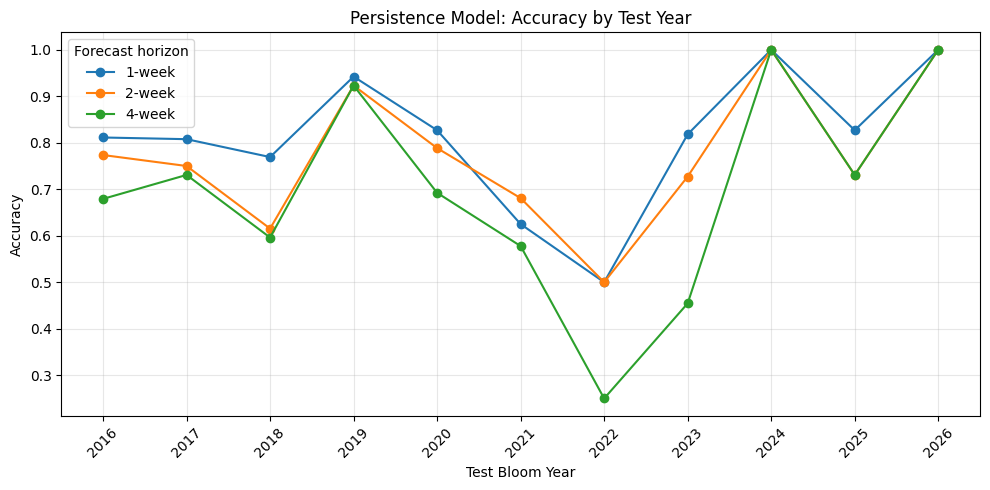

In [7]:
plt.figure(figsize=(10, 5))

for horizon in [1, 2, 4]:

    horizon_results = results_df[results_df["horizon"] == horizon].sort_values("test_year")

    plt.plot(
        horizon_results["test_year"],
        horizon_results["accuracy"],
        marker="o",
        label=f"{horizon}-week"
    )

plt.xlabel("Test Bloom Year")
plt.ylabel("Accuracy")
plt.title("Persistence Model: Accuracy by Test Year")
plt.xticks(range(2016, 2027), rotation=45)
plt.legend(title="Forecast horizon")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

## Macro-F1 by Test Year

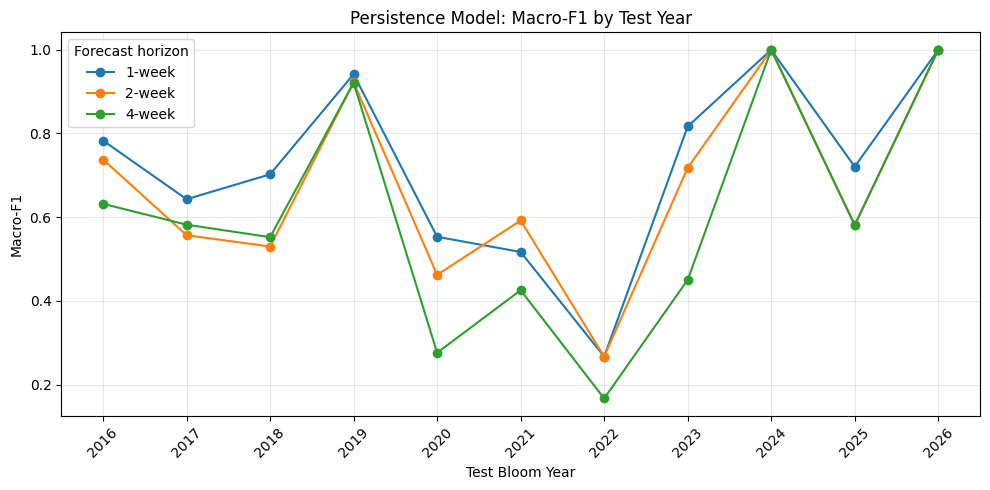

In [8]:
# Plot test-year macro-F1 for each prediction horizon
plt.figure(figsize=(10, 5))

for horizon in [1, 2, 4]:

    horizon_results = results_df[results_df["horizon"] == horizon].sort_values("test_year")

    plt.plot(
        horizon_results["test_year"],
        horizon_results["macro_f1"],
        marker="o",
        label=f"{horizon}-week"
    )

plt.xlabel("Test Bloom Year")
plt.ylabel("Macro-F1")
plt.title("Persistence Model: Macro-F1 by Test Year")
plt.xticks(range(2016, 2027), rotation=45)
plt.legend(title="Forecast horizon")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

## ROC-AUC by Test Year

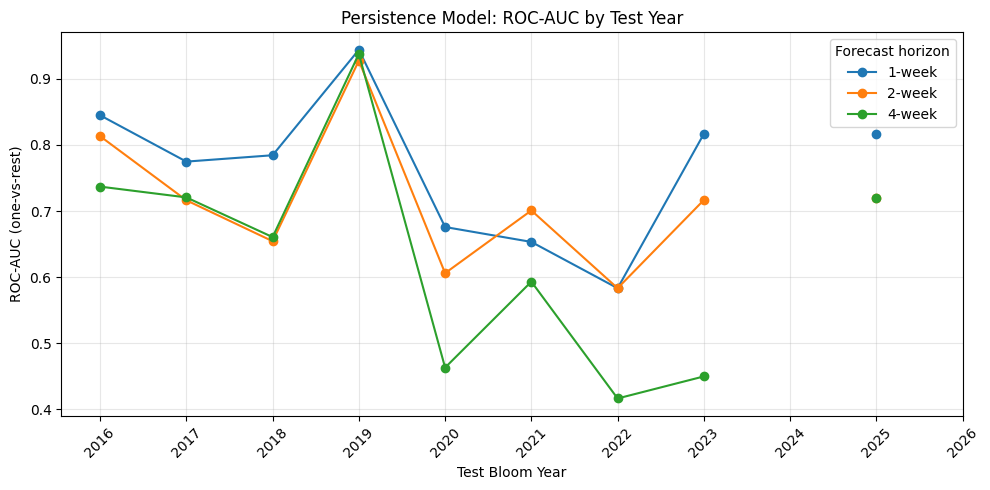

In [9]:
plt.figure(figsize=(10, 5))

for horizon in [1, 2, 4]:

    horizon_results = results_df[results_df["horizon"] == horizon].sort_values("test_year")

    plt.plot(
        horizon_results["test_year"],
        horizon_results["roc_auc_ovr"],
        marker="o",
        label=f"{horizon}-week"
    )

plt.xlabel("Test Bloom Year")
plt.ylabel("ROC-AUC (one-vs-rest)")
plt.title("Persistence Model: ROC-AUC by Test Year")
plt.xticks(range(2016, 2027), rotation=45)
plt.legend(title="Forecast horizon")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

## Save the Model

A persistence model has no learned weights, because the forecast is just the most recent observed class. Instead, the rule itself needs to be saved.

The saved file resulting from this code cell contains no results from the evaluation, and only the rule.

In [10]:
# Folder for saved models
MODEL_DIR = os.path.join(os.getcwd(), "models")
os.makedirs(MODEL_DIR, exist_ok=True)

persistence_config = {
    "model": "persistence",
    "description": "Forecast for any horizon equals the most recent observed bloom class.",
    "input_column": PERSISTENCE_COLUMN,
    "horizons_weeks": [1, 2, 4],
    "classes": CLASSES,
    "learned_parameters": None,
}

config_path = os.path.join(MODEL_DIR, "persistence_config.json")

with open(config_path, "w") as f:
    json.dump(persistence_config, f, indent=2)

print(f"Saved persistence model definition -> {config_path}")

Saved persistence model definition -> /content/drive/MyDrive/BTT Fall AI Studio 2026/Google Colab/data/models/persistence_config.json


## Load the Saved Model

In [11]:
with open(os.path.join(MODEL_DIR, "persistence_config.json")) as f:
    loaded_config = json.load(f)

recent_weeks = dataset.tail(5)

predicted_class = recent_weeks[loaded_config["input_column"]].astype(int)

example_predictions = pd.DataFrame({
    "week_ending": recent_weeks["week_ending"].dt.date,
    "input_class": recent_weeks[loaded_config["input_column"]].astype(int).values,
    "predicted_class (all horizons)": predicted_class.values,
})

print(f"Persistence model, horizons {loaded_config['horizons_weeks']} weeks")
print(example_predictions.to_string(index=False))

Persistence model, horizons [1, 2, 4] weeks
week_ending  input_class  predicted_class (all horizons)
 2026-04-05            0                               0
 2026-04-12            0                               0
 2026-04-19            0                               0
 2026-04-26            0                               0
 2026-05-03            0                               0


## Model Performance Summary

| Forecast horizon | Model | Accuracy | Macro-F1 | Macro-precision | Macro-recall | ROC-AUC (OvR) |
| --- | --- | --- | --- | --- | --- | --- |
| 1 week | Persistence | 81.16% | 0.7221 | 0.7291 | 0.7175 | 0.7659 |
| 2 weeks | Persistence | 77.18% | 0.6696 | 0.6788 | 0.6647 | 0.7153 |
| 4 weeks | Persistence | 69.41% | 0.5987 | 0.6162 | 0.5949 | 0.6332 |

## Conclusion

Performance declined as the horizon increased, from 81.16% accuracy and 0.7221 macro-F1 at one week to 69.41% accuracy and 0.5987 macro-F1 at four weeks. This is expected, because the longer the horizon, the more time conditions have to change.

Performance varied widely by year. The model was perfect in 2024 and 2026 at every horizon, but weaker in 2021. Accuracy also hid some weaknesses, showing that most of the errors fell on the rarer bloom classes. Since persistence makes hard class predictions rather than probabilities, ROC-AUC is limited. It could not be computed for 2024 and 2026, where the test weeks did not contain enough classes, and it fell below 0.5 in a few weak years. Lastly, several test years contain very few weeks, so small differences in mean performance should not be treated as conclusive.

## Resources

1. https://scikit-learn.org/stable/modules/model_evaluation.html
2. https://scikit-learn.org/stable/modules/generated/sklearn.metrics.roc_auc_score.html